# Hydrological Data

,Date,Segment_id,x,y,Evapotranspiration,Precipitation,Irrigation_pumping,Observed,DateTime
0,710732,144,1086190,14476800,0.59,18.99,0.0,0.145161,1945-12-02
1,710763,144,1086190,14476800,0.97,29.63,0.0,0.445161,1946-01-02
2,710791,144,1086190,14476800,1.34,29.63,0.0,1.332203,1946-01-30
3,710822,144,1086190,14476800,1.79,29.63,0.0,2.932203,1946-03-02
4,710852,144,1086190,14476800,8.23,29.63,0.0,3.728689,1946-04-01


<Axes: xlabel='x', ylabel='y'>

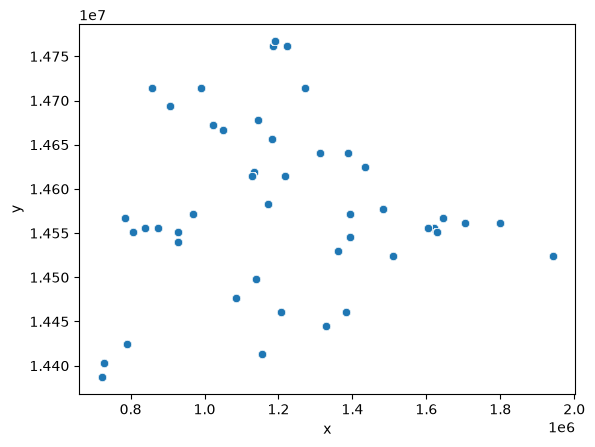

In [1]:
import pandas as pd
import seaborn as sns

df = pd.read_csv('data/RRCA_baseflow.csv')
# Date is days since 1/1/0000
df['DateTime'] = pd.to_datetime(df['Date'], unit='D', origin='0000-1-1')

display(df.head(5))

segments = df.copy()
segments.drop_duplicates(subset=['Segment_id'], keep='first')
segments

sns.scatterplot(data=segments, x='x', y='y')

Presumably the correlations will be a bit different for each segment. I wonder how/if you can account for that. Do we just have to leave out segment? Maybe there's a consistent relationship as x or y increases by I kinda doubt it.

It seems like the river branches out as you go left (idk whether it's a delta or those are tributaries). Either way `x` could be a meaningful feature. I doubt `y` would have any significant correlation.

In [2]:
# Date range
print(f'min {df['DateTime'].min()} max {df['DateTime'].max()}')

# Research events during time range

# Overlay map

min 1939-10-02 00:00:00 max 2000-09-01 00:00:00


Where/When is this?
Dates: 10/2/1939 - 9/1/2000

Republican River Basin - a 15.9-million-acre watershed spanning northeastern Colorado, southwestern Nebraska, and northwestern Kansas

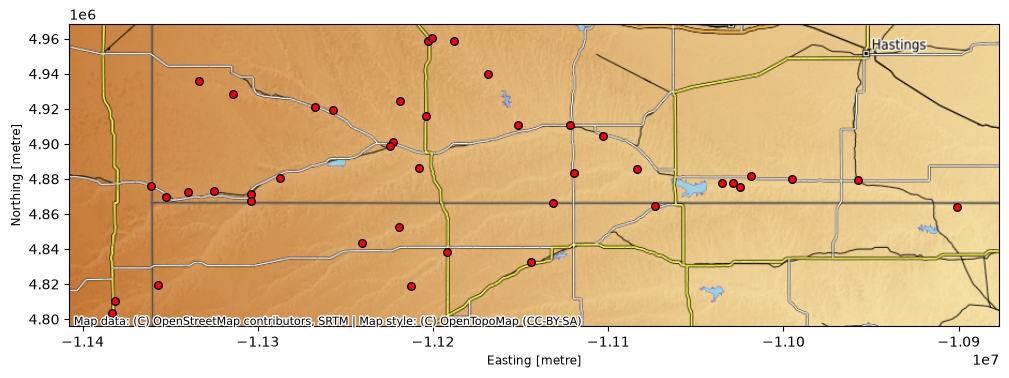

In [ ]:
import pandas as pd, geopandas as gpd, contextily as cx, matplotlib.pyplot as plt

df = pd.read_csv("data/RRCA_baseflow.csv").drop_duplicates("Segment_id")
gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.x * 0.3048, df.y * 0.3048),
                       crs="EPSG:26914").to_crs(epsg=3857)   # UTM 14 (ft -> m) -> web mercator
ax = gdf.plot(figsize=(12, 6), color="red", markersize=30, edgecolor="k")
cx.add_basemap(ax, source=cx.providers.Esri.WorldImagery)  # or cx.providers.Esri.WorldImagery
plt.show()